# Experiment 5: Fine-Tuning GAN Models for High-Resolution Image Generation

**Aim:** Implement a *progressively growing* GAN (ProGAN-style) that is first trained on low-resolution images and then
fine-tuned stage by stage to 64x64, and study how fine-tuning from a pre-trained low-resolution model and the choice of
learning rate affect the quality of the generated images.

In [1]:
import os, time, copy
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scipy import linalg
keras.utils.set_random_seed(21)
rng = np.random.default_rng(21)
LATENT, BATCH = 128, 64
RES = [8, 16, 32, 64]
CH = {4: 128, 8: 128, 16: 96, 32: 64, 64: 32}      # feature maps per resolution
N_IMG = 20000
print("TensorFlow", tf.__version__, "| resolutions:", RES, "| latent:", LATENT)

I0000 00:00:1792706584.298567   16012 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792706585.483910   16012 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | resolutions: [8, 16, 32, 64] | latent: 128


## 1. Data at several resolutions
Fashion-MNIST (28x28) is resized with anti-aliased bilinear interpolation to every training resolution.

 8x8  : (20000, 8, 8, 1), range [-1.00, 1.00]
16x16 : (20000, 16, 16, 1), range [-1.00, 1.00]
32x32 : (20000, 32, 32, 1), range [-1.00, 1.00]
64x64 : (20000, 64, 64, 1), range [-1.00, 1.00]


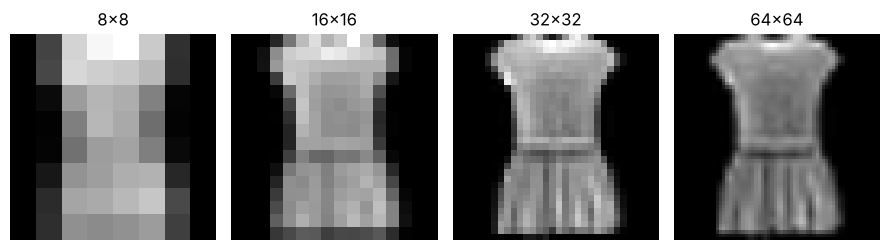

In [2]:
(x_all, y_all), (x_te, y_te) = keras.datasets.fashion_mnist.load_data()
x_all = x_all[:N_IMG, ..., None].astype("float32") / 127.5 - 1
data = {r: tf.image.resize(x_all, (r, r), antialias=True).numpy() for r in RES}
for r in RES: print(f"{r:2d}x{r:<2d} : {data[r].shape}, range [{data[r].min():.2f}, {data[r].max():.2f}]")
fig, axes = plt.subplots(1, 4, figsize=(9, 2.5))
for a, r in zip(axes, RES):
    a.imshow(data[r][3, ..., 0], cmap="gray", interpolation="nearest"); a.set_title(f"{r}x{r}"); a.axis("off")
plt.tight_layout(); plt.show()

## 2. Progressive architecture
*Design note:* the generator output is **linear** (no `tanh`), as in ProGAN. A first version with a `tanh` output saturated within a few
steps, the generator collapsed to a constant image and the discriminator loss fell to zero; removing the saturating output fixed it.
The generator starts from a 4x4 feature map; each new block doubles the resolution. When a block is added, its output is
**faded in**: $\text{out}=(1-\alpha)\cdot\text{upsample}(\text{old\_output})+\alpha\cdot\text{new\_output}$ with
$\alpha$ rising from 0 to 1, so the already-trained layers are *fine-tuned* smoothly instead of being shocked by the new
layers. The discriminator mirrors this with its own fade-in on the input side.

In [3]:
class PixelNorm(layers.Layer):
    def call(self, x): return x * tf.math.rsqrt(tf.reduce_mean(tf.square(x), -1, keepdims=True) + 1e-8)

ALPHA = tf.Variable(1.0, trainable=False)         # fade-in coefficient shared by G and D
class Fade(layers.Layer):
    def call(self, inputs): old, new = inputs; return (1 - ALPHA) * old + ALPHA * new

def conv(c): return layers.Conv2D(c, 3, padding="same")
def lrelu(): return layers.LeakyReLU(0.2)

def make_nets():
    n = {}
    n["g_base"] = keras.Sequential([layers.Input((LATENT,)), layers.Dense(4 * 4 * CH[4]), layers.Reshape((4, 4, CH[4])),
                                    lrelu(), PixelNorm(), conv(CH[4]), lrelu(), PixelNorm()])
    n["g_blocks"] = {r: keras.Sequential([layers.Input((r // 2, r // 2, CH[r // 2])), layers.UpSampling2D(),
                                          conv(CH[r]), lrelu(), PixelNorm(), conv(CH[r]), lrelu(), PixelNorm()]) for r in RES}
    n["to_img"] = {r: keras.Sequential([layers.Input((r, r, CH[r])), layers.Conv2D(1, 1)]) for r in [4] + RES}
    n["from_img"] = {r: keras.Sequential([layers.Input((r, r, 1)), layers.Conv2D(CH[r], 1), lrelu()]) for r in [4] + RES}
    n["d_blocks"] = {r: keras.Sequential([layers.Input((r, r, CH[r])), conv(CH[r]), lrelu(), conv(CH[r // 2]), lrelu(),
                                          layers.AveragePooling2D(2)]) for r in RES}
    n["d_final"] = keras.Sequential([layers.Input((4, 4, CH[4])), conv(CH[4]), lrelu(), layers.Flatten(),
                                     layers.Dense(CH[4]), lrelu(), layers.Dense(1)])
    return n

def build_G(n, r, fade=False):
    z = keras.Input((LATENT,)); x = n["g_base"](z)
    for q in RES:
        if q < r: x = n["g_blocks"][q](x)
    if fade:
        old = layers.UpSampling2D()(n["to_img"][r // 2](x))
        out = Fade()([old, n["to_img"][r](n["g_blocks"][r](x))])
    else:
        out = n["to_img"][r](n["g_blocks"][r](x))
    return keras.Model(z, out, name=f"G{r}")      # linear output (as in ProGAN); a tanh output saturated and killed the generator

def build_D(n, r, fade=False):
    inp = keras.Input((r, r, 1)); x = n["d_blocks"][r](n["from_img"][r](inp))
    if fade: x = Fade()([n["from_img"][r // 2](layers.AveragePooling2D(2)(inp)), x])
    for q in reversed(RES):
        if q < r: x = n["d_blocks"][q](x)
    return keras.Model(inp, n["d_final"](x), name=f"D{r}")

nets = make_nets()
for r in (8, 32, 64):
    g, d = build_G(nets, r), build_D(nets, r)
    print(f"stage {r:2d}x{r:<2d}: G output {g.output_shape[1:]}  ({g.count_params():>9,} params) | D input {d.input_shape[1:]}  ({d.count_params():>9,} params)")

stage  8x8 : G output (8, 8, 1)  (  707,073 params) | D input (8, 8, 1)  (  705,409 params)
stage 32x32: G output (32, 32, 1)  (  993,025 params) | D input (32, 32, 1)  (  991,361 params)
stage 64x64: G output (64, 64, 1)  (1,020,705 params) | D input (64, 64, 1)  (1,019,041 params)


In [4]:
def train_stage(n, r, steps, fade, lr=1e-4, log=None, beta1=0.5):
    G, D = build_G(n, r, fade), build_D(n, r, fade)
    g_opt, d_opt = keras.optimizers.Adam(lr, beta1, 0.99), keras.optimizers.Adam(lr, beta1, 0.99)
    @tf.function
    def step(real):
        z = tf.random.normal((tf.shape(real)[0], LATENT))
        with tf.GradientTape() as gt, tf.GradientTape() as dt:
            fake = G(z, training=True)
            rl, fl = D(real, training=True), D(fake, training=True)
            d_loss = 0.5 * (tf.reduce_mean((rl - 1) ** 2) + tf.reduce_mean(fl ** 2))
            g_loss = 0.5 * tf.reduce_mean((fl - 1) ** 2)
        g_opt.apply_gradients(zip(gt.gradient(g_loss, G.trainable_variables), G.trainable_variables))
        d_opt.apply_gradients(zip(dt.gradient(d_loss, D.trainable_variables), D.trainable_variables))
        return g_loss, d_loss
    losses = []
    for s in range(steps):
        ALPHA.assign((s + 1) / steps if fade else 1.0)
        g, d = step(data[r][rng.integers(0, N_IMG, BATCH)])
        losses.append((float(g), float(d)))
    ALPHA.assign(1.0)
    return G, np.array(losses)

# Frechet distance in the feature space of an independent classifier (a lightweight stand-in for FID)
(xc, yc) = data[32], y_all[:N_IMG]
clf = keras.Sequential([layers.Input((32, 32, 1)), layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
                        layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(), layers.Flatten(),
                        layers.Dense(64, activation="relu", name="feat"), layers.Dense(10, activation="softmax")])
clf.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
clf.fit(xc, yc, epochs=4, batch_size=128, verbose=0)
x_te32 = tf.image.resize(x_te[:2000, ..., None].astype("float32") / 127.5 - 1, (32, 32), antialias=True).numpy()
print("feature-extractor classifier test accuracy (32x32): %.4f" % clf.evaluate(x_te32, y_te[:2000], verbose=0)[1])
feat = keras.Model(clf.inputs, clf.get_layer("feat").output)
def frechet(a, b):
    mu1, mu2 = a.mean(0), b.mean(0); s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    cs = linalg.sqrtm(s1 @ s2).real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * cs))
real_feat = feat.predict(x_te32, verbose=0)
print("sanity: FD(real, real halves) = %.2f   FD(real, noise) = %.1f" % (
    frechet(real_feat[:1000], real_feat[1000:]), frechet(real_feat, feat.predict(np.random.uniform(-1, 1, (2000, 32, 32, 1)).astype("float32"), verbose=0))))
def fd_of(G, r=32, n=2000):
    imgs = np.clip(np.concatenate([G(tf.random.normal((250, LATENT)), training=False).numpy() for _ in range(n // 250)]), -1, 1)   # chunks keep memory low
    if r != 32: imgs = tf.image.resize(imgs, (32, 32), antialias=True).numpy()
    return frechet(real_feat, feat.predict(imgs, verbose=0))

feature-extractor classifier test accuracy (32x32): 0.8680


/tmp/ipykernel_16012/2408052576.py:35: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cs = linalg.sqrtm(s1 @ s2).real


sanity: FD(real, real halves) = 1.40   FD(real, noise) = 327.9


## 3. Progressive training: 8x8 -> 16x16 -> 32x32 -> 64x64
Each new resolution is first trained with fade-in and then stabilised, starting from the weights of the previous stage.

In [5]:
STEPS = {8: (0, 700), 16: (350, 350), 32: (350, 350), 64: (350, 350)}   # (fade-in steps, stable steps)
fixed_z = tf.random.normal((16, LATENT), seed=1)
samples, all_losses, pretrained = {}, [], {}
t0 = time.time()
for r in RES:
    nf, ns = STEPS[r]
    if nf:
        _, l1 = train_stage(nets, r, nf, fade=True); all_losses.append(l1)
    G, l2 = train_stage(nets, r, ns, fade=False); all_losses.append(l2)
    samples[r] = np.clip(G(fixed_z, training=False).numpy(), -1, 1)
    if r == 16:                                         # keep the 16x16 model as a "pre-trained" checkpoint
        pretrained = copy.deepcopy({k: ({q: [w.copy() for w in m.get_weights()] for q, m in v.items()} if isinstance(v, dict)
                                        else [w.copy() for w in v.get_weights()]) for k, v in nets.items()})
    fd = fd_of(G, r)
    print(f"stage {r:2d}x{r:<2d} finished ({nf} fade-in + {ns} stable steps)  loss G/D = {l2[-50:, 0].mean():.3f}/{l2[-50:, 1].mean():.3f}   "
          f"Frechet distance = {fd:6.2f}   [{time.time() - t0:.0f}s]")
G_final = G

/tmp/ipykernel_16012/2408052576.py:35: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cs = linalg.sqrtm(s1 @ s2).real


stage  8x8  finished (0 fade-in + 700 stable steps)  loss G/D = 0.284/0.127   Frechet distance = 114.29   [66s]


stage 16x16 finished (350 fade-in + 350 stable steps)  loss G/D = 0.201/0.183   Frechet distance =  60.30   [296s]


stage 32x32 finished (350 fade-in + 350 stable steps)  loss G/D = 0.210/0.186   Frechet distance =  31.18   [884s]


stage 64x64 finished (350 fade-in + 350 stable steps)  loss G/D = 0.197/0.196   Frechet distance =  38.73   [2105s]


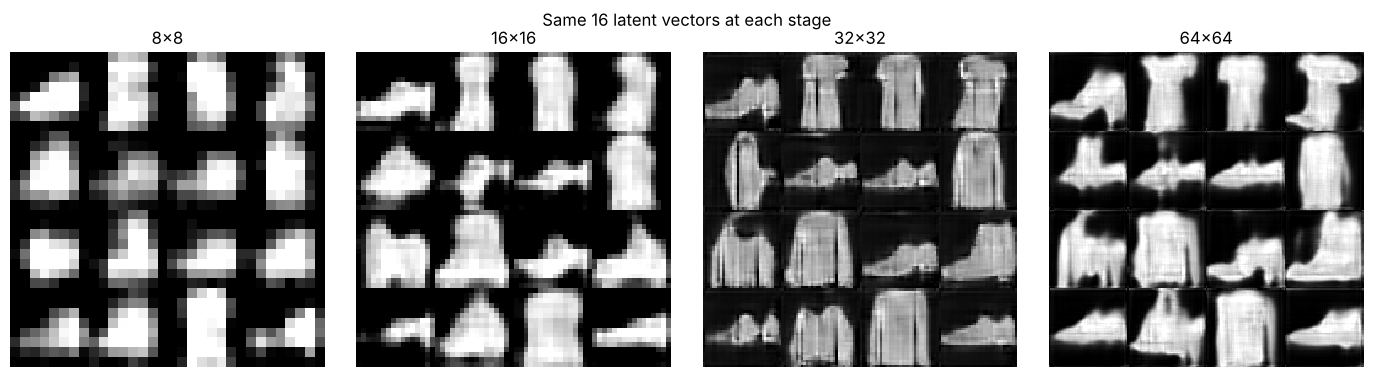

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for a, r in zip(axes, RES):
    s = (samples[r][..., 0] + 1) / 2
    a.imshow(np.concatenate([np.concatenate(s[i * 4:(i + 1) * 4], 1) for i in range(4)], 0), cmap="gray", interpolation="nearest")
    a.set_title(f"{r}x{r}"); a.axis("off")
plt.suptitle("Same 16 latent vectors at each stage"); plt.tight_layout(); plt.show()

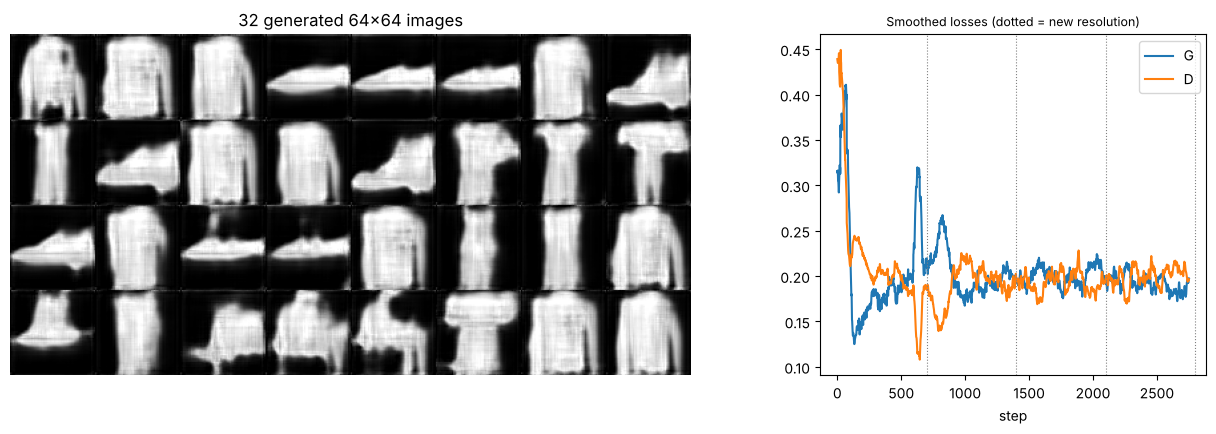

In [7]:
g64 = (np.clip(G_final(tf.random.normal((32, LATENT), seed=77), training=False).numpy()[..., 0], -1, 1) + 1) / 2
fig = plt.figure(figsize=(13, 4.4)); gs = fig.add_gridspec(1, 3)
a = fig.add_subplot(gs[0, :2]); a.imshow(np.concatenate([np.concatenate(g64[i * 8:(i + 1) * 8], 1) for i in range(4)], 0), cmap="gray")
a.axis("off"); a.set_title("32 generated 64x64 images")
b = fig.add_subplot(gs[0, 2]); L = np.concatenate(all_losses)
k = 50; sm = lambda v: np.convolve(v, np.ones(k) / k, "valid")
b.plot(sm(L[:, 0]), label="G"); b.plot(sm(L[:, 1]), label="D")
off = 0
for r, (nf, ns) in STEPS.items():
    off += nf + ns; b.axvline(off, c="gray", ls=":", lw=0.8)
b.set_title("Smoothed losses (dotted = new resolution)"); b.set_xlabel("step"); b.legend(); b.title.set_fontsize(9)
plt.tight_layout(); plt.show()

## 4. Fine-tuning study at 32x32
Same budget (700 steps) and same data, four ways of getting a 32x32 generator:
* **scratch** - train all layers from random initialisation directly at 32x32;
* **fine-tune** - start from the pre-trained 16x16 model, fade in the 32x32 block, using learning rates 2.5e-5, 1e-4 and 5e-4.

In [8]:
def load(n, ckpt):
    for k, v in ckpt.items():
        if isinstance(v, dict):
            for q, w in v.items(): n[k][q].set_weights(w)
        else: n[k].set_weights(v)
results, gens = {}, {}
BUDGET = 700
configs = [("scratch, lr 1e-4", False, 1e-4), ("fine-tune, lr 2.5e-5", True, 2.5e-5),
           ("fine-tune, lr 1e-4", True, 1e-4), ("fine-tune, lr 5e-4", True, 5e-4)]
for name, ft, lr in configs:
    keras.utils.set_random_seed(5)
    n = make_nets()
    if ft:
        load(n, pretrained)
        _, a = train_stage(n, 32, BUDGET // 2, fade=True, lr=lr)
        G, b = train_stage(n, 32, BUDGET - BUDGET // 2, fade=False, lr=lr)
    else:
        G, b = train_stage(n, 32, BUDGET, fade=False, lr=lr)
    results[name] = fd_of(G); gens[name] = np.clip(G(fixed_z, training=False).numpy(), -1, 1)
    print(f"{name:22s} -> Frechet distance {results[name]:7.2f}")

/tmp/ipykernel_16012/2408052576.py:35: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cs = linalg.sqrtm(s1 @ s2).real


scratch, lr 1e-4       -> Frechet distance  277.78


fine-tune, lr 2.5e-5   -> Frechet distance   52.70


fine-tune, lr 1e-4     -> Frechet distance   56.13


fine-tune, lr 5e-4     -> Frechet distance   37.69


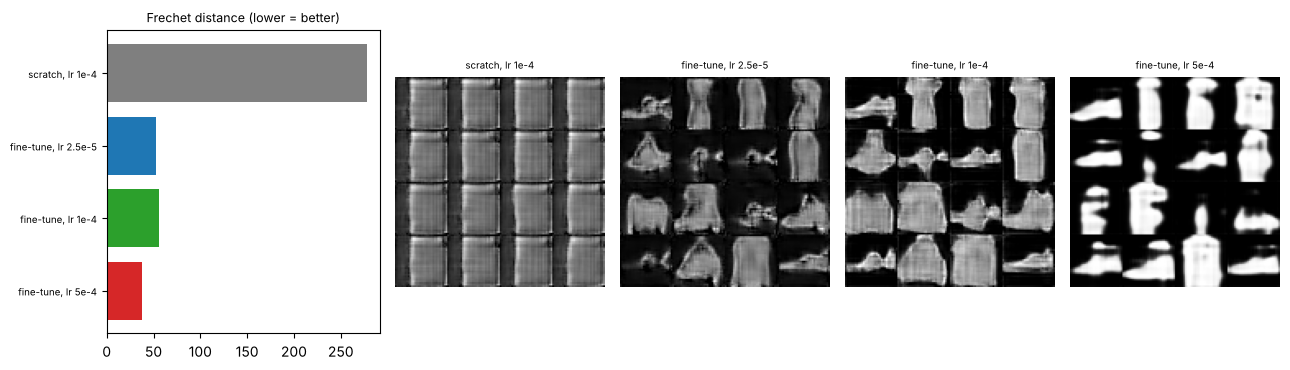

Best configuration: fine-tune, lr 5e-4 | improvement over scratch: 86.4%


In [9]:
fig = plt.figure(figsize=(13, 3.8)); gs = fig.add_gridspec(1, 5, width_ratios=[1.3, 1, 1, 1, 1])
ax = fig.add_subplot(gs[0, 0]); names = list(results)
cols = ["tab:gray", "tab:blue", "tab:green", "tab:red"]
ax.barh(range(4), [results[k] for k in names], color=cols); ax.set_yticks(range(4)); ax.set_yticklabels(names, fontsize=7)
ax.invert_yaxis(); ax.set_title("Frechet distance (lower = better)", fontsize=9)
for i, k in enumerate(names):
    a = fig.add_subplot(gs[0, i + 1]); s = (gens[k][..., 0] + 1) / 2
    a.imshow(np.concatenate([np.concatenate(s[j * 4:(j + 1) * 4], 1) for j in range(4)], 0), cmap="gray"); a.axis("off")
    a.set_title(k, fontsize=7)
plt.tight_layout(); plt.show()
best = min(results, key=results.get)
print("Best configuration:", best, "| improvement over scratch: %.1f%%" % (100 * (1 - results[best] / results["scratch, lr 1e-4"])))